In [1]:
# Import Libiraries
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

In [3]:
# Ste1: Get and frame. Load train.csv, pick one store, build a datetime index at daily
#frequency, and decide explicitly what to do with closed days.
# Load the dataset
df = pd.read_csv("Rossman_store.csv")


# Pick exactly one store
df_store = df[df["Store"] == 1].copy()


# Convert to datetime using the correct format
df_store["Date"] = pd.to_datetime(df_store["Date"], format="%Y-%m-%d")

# Set the date as the index and sort chronologically
df_store = df_store.set_index("Date").sort_index()
df_store

C:\Users\kazee\AppData\Local\Temp\ipykernel_7528\2236173106.py:2: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Rossman_store.csv")


,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
Date,,,,,,,,
2013-01-01,1,2,0,0,0,0,a,1
2013-01-02,1,3,5530,668,1,0,0,1
2013-01-03,1,4,4327,578,1,0,0,1
2013-01-04,1,5,4486,619,1,0,0,1
2013-01-05,1,6,4997,635,1,0,0,1
...,...,...,...,...,...,...,...,...
2015-07-27,1,1,6102,612,1,1,0,1
2015-07-28,1,2,5011,560,1,1,0,1
2015-07-29,1,3,4782,523,1,1,0,1


In [4]:
# Handle Closed Days
df_store.loc[df_store['Open'] == 0, 'Sales'] = 0

#Enforce a Clean Daily Frequency
# Enforce a strict daily sequence
df_store = df_store.asfreq("D")

# Impute any newly created missing values (NaNs) that appeared from enforcing the grid
# For example, if a day was missing entirely from the file, fill its sales with 0
df_store["Sales"] = df_store["Sales"].fillna(0)


In [5]:
# Verify the Timeline
start_date = df_store.index.min()
max_date = df_store.index.max()
date_range = pd.date_range(start_date, max_date, freq="D")

print(f"Expected Days: {len(date_range)} | Available Days in Data: {len(df_store)}")

Expected Days: 942 | Available Days in Data: 942


In [9]:
# Count missing values in each column
print(df_store.isnull().sum())

Store            0
DayOfWeek        0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64


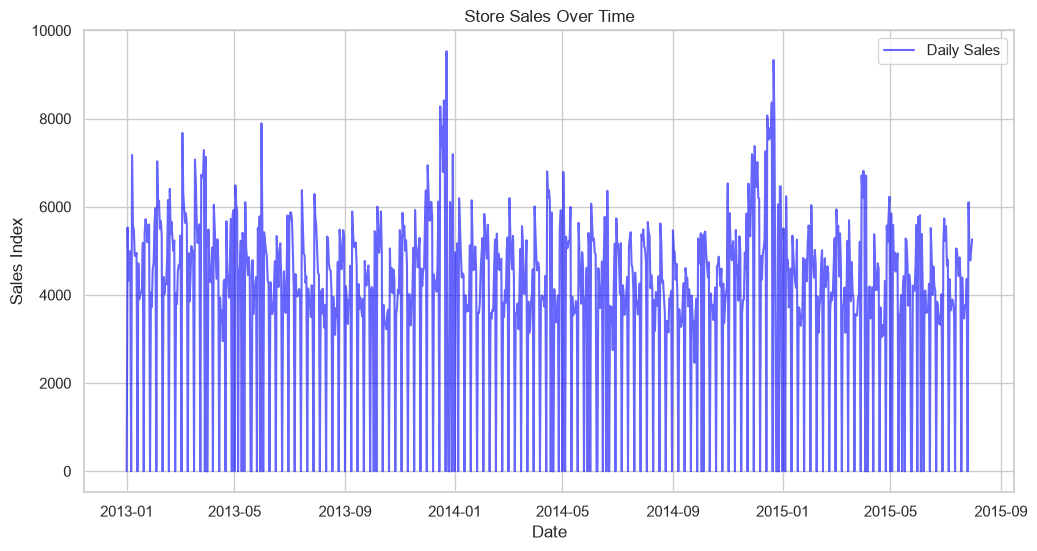

In [16]:
# Step 2: Explore and decompose. Plot the series. Decompose it and identify the weekly and annual cycles. 
# Decide additive or multiplicative and justify it
# Visualise the Time Series (Plotting)

# Plot the entire sales history
plt.figure(figsize=(12, 6))
sns.set_theme(style = "whitegrid")
plt.plot(df_store.index, df_store['Sales'], label='Daily Sales', color='blue', alpha=0.6)
plt.title('Store Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Sales Index')
plt.legend()
plt.show()

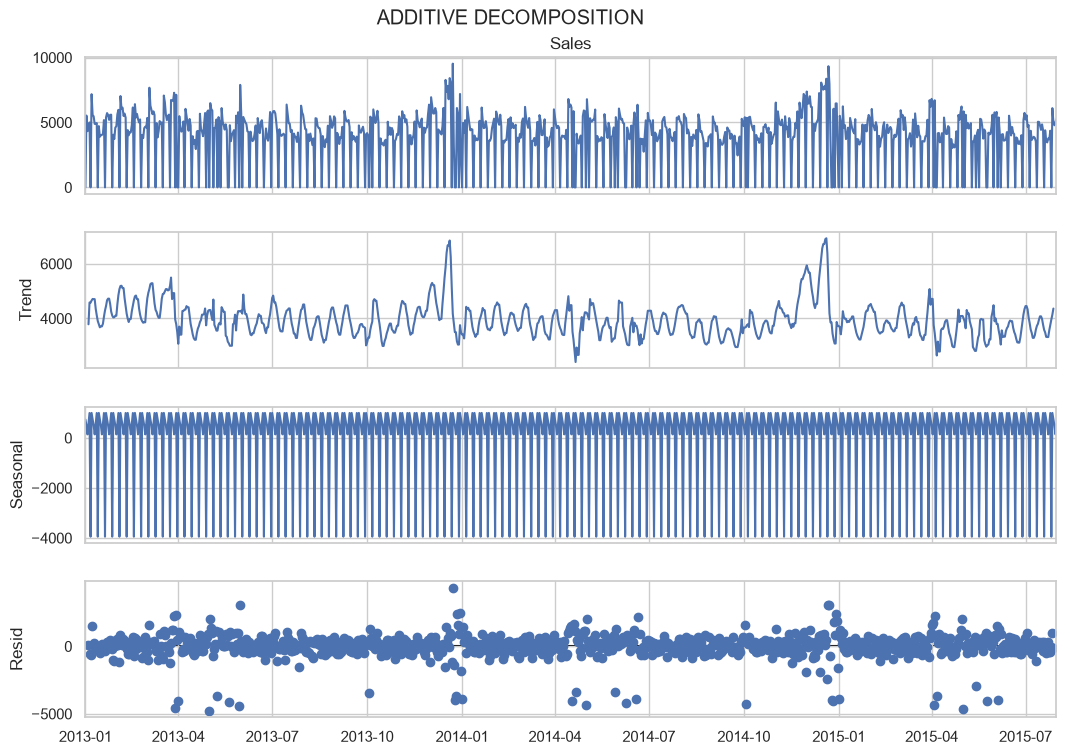

In [72]:
# Decomposition targeting the Weekly Cycle- Additive Model
result_weekly = seasonal_decompose(df_store['Sales'], model='additive', period=7)

# Plot the decomposed components (Trend, Seasonal, Residuals)
fig = result_weekly.plot()
fig.set_size_inches(12, 8)
fig.suptitle("ADDITIVE DECOMPOSITION")
plt.show()

In [32]:
# Identify the Weekly Cycle
# Extract the extracted weekly pattern and group by day of the week
df_store['Weekly_Pattern'] = result_weekly.seasonal
weekly_profile = df_store.groupby(df_store.index.day_name())['Weekly_Pattern'].mean()

# Reorder logically starting Monday
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekly_profile = weekly_profile.reindex(days_order)

print("Weekly Seasonal Values by Day:")
print(weekly_profile)

Weekly Seasonal Values by Day:
Date
Monday        999.479481
Tuesday       738.158585
Wednesday     500.263536
Thursday      142.240979
Friday        569.486943
Saturday      996.271592
Sunday      -3945.901116
Name: Weekly_Pattern, dtype: float64


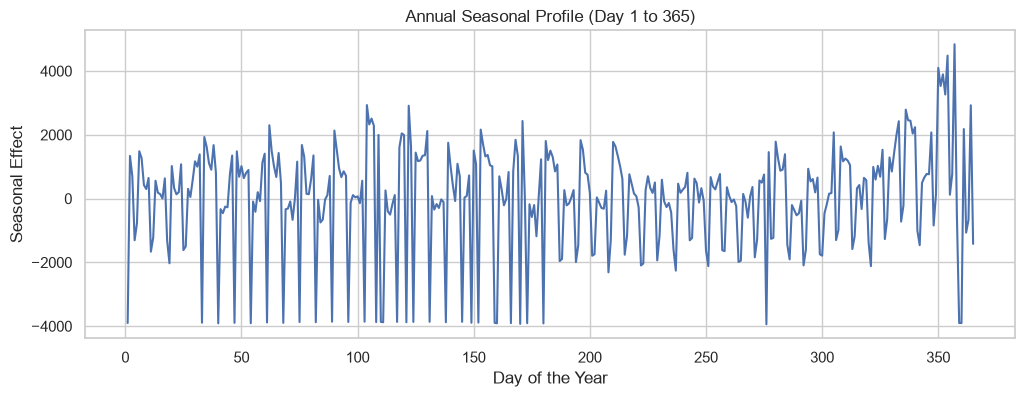

In [33]:
# Identify the Annual Cycle
# Decomposition targeting the Annual Cycle (period=365 days)
result_annual = seasonal_decompose(df_store['Sales'], model='additive', period=365)

# Extract and plot just the annual seasonal component 
plt.figure(figsize=(12, 4))
plt.plot(result_annual.seasonal.iloc[:365].index.dayofyear, result_annual.seasonal.iloc[:365].values)
plt.title('Annual Seasonal Profile (Day 1 to 365)')
plt.xlabel('Day of the Year')
plt.ylabel('Seasonal Effect')
plt.show()

In [34]:
# Step 3: Split and baseline. Hold out the final six weeks. Compute naive, seasonal naive
# moving average and drift forecasts, and score them. This is your bar
# Split the Data (Hold Out Final 6 Weeks)
#  Test horizon (6 weeks = 42 days)
horizon = 42

# Split into train and test sets
train = df_store.iloc[:-horizon].copy()
test = df_store.iloc[-horizon:].copy()

print(f"Training Data Range: {train.index.min().date()} to {train.index.max().date()} ({len(train)} days)")
print(f"Testing Data Range: {test.index.min().date()} to {test.index.max().date()} ({len(test)} days)")


Training Data Range: 2013-01-01 to 2015-06-19 (900 days)
Testing Data Range: 2015-06-20 to 2015-07-31 (42 days)


In [35]:
# Generate the Baseline Forecasts
# Create a dataframe to store all test results
forecasts = pd.DataFrame(index=test.index)
forecasts['Actual'] = test['Sales']

# Naive Forecast 
last_value = train['Sales'].iloc[-1]
forecasts['Naive'] = last_value

# Seasonal Naive Forecast 
forecasts['Seasonal_Naive'] = train['Sales'].iloc[-horizon:].values

# Moving Average Forecast
# Strategy: Take the average of the last 'N' days of training data (e.g., a 14-day window)
window_size = 14
ma_value = train['Sales'].iloc[-window_size:].mean()
forecasts['Moving_Average'] = ma_value

# Drift Forecast 
y_first = train['Sales'].iloc[0]
y_last = train['Sales'].iloc[-1]
n_train = len(train)

# Calculate the average daily change (slope)
slope = (y_last - y_first) / (n_train - 1)
# Project the slope forward into the test period
forecasts['Drift'] = [y_last + (slope * (i + 1)) for i in range(horizon)]

In [36]:
# Score the Baseline Models
# Create a container for our evaluation report
metrics_list = []

# List out the models we generated
baseline_models = ['Naive', 'Seasonal_Naive', 'Moving_Average', 'Drift']

for model in baseline_models:
    mae = mean_absolute_error(forecasts['Actual'], forecasts[model])
    rmse = np.sqrt(mean_squared_error(forecasts['Actual'], forecasts[model]))
    
    metrics_list.append({
        'Model': model,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2)
})

# Convert directly to a DataFrame to view the scorecard
scorecard = pd.DataFrame(metrics_list)
print("--- Baseline Evaluation Scorecard ---")
print(scorecard)

--- Baseline Evaluation Scorecard ---
            Model      MAE     RMSE
0           Naive  1150.57  1734.59
1  Seasonal_Naive   721.81  1268.10
2  Moving_Average  1223.39  1684.42
3           Drift  1136.07  1754.76


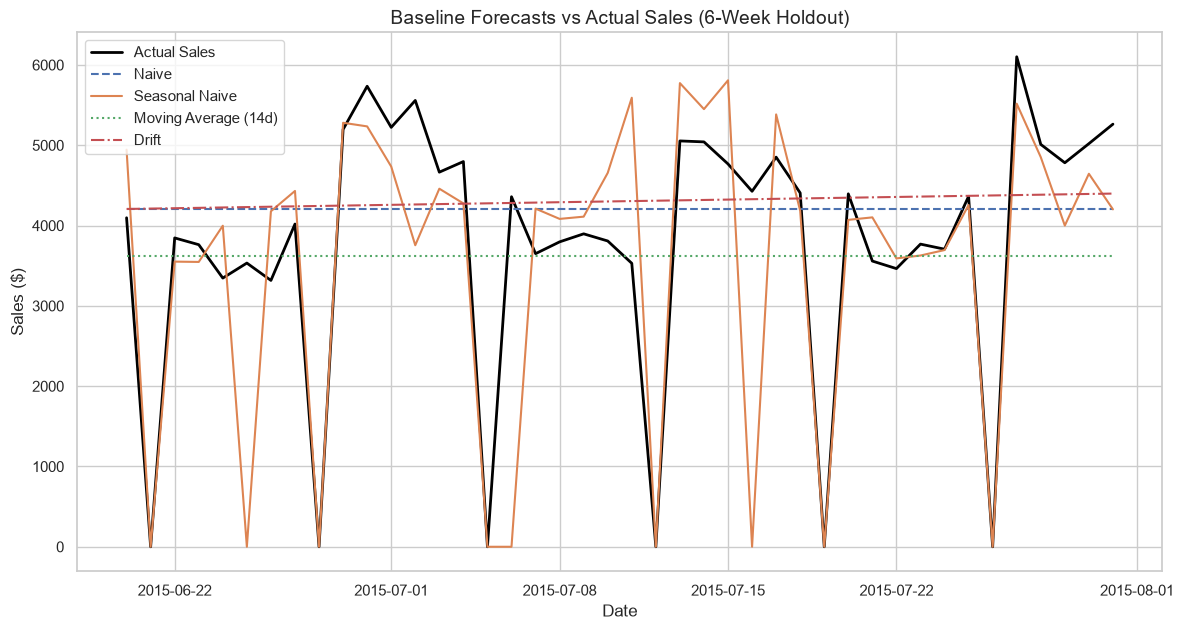

In [37]:
# Plot the Baselines Against Actuals
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))
plt.plot(forecasts.index, forecasts['Actual'], label='Actual Sales', color='black', linewidth=2)
plt.plot(forecasts.index, forecasts['Naive'], label='Naive', linestyle='--')
plt.plot(forecasts.index, forecasts['Seasonal_Naive'], label='Seasonal Naive', linestyle='-')
plt.plot(forecasts.index, forecasts['Moving_Average'], label='Moving Average (14d)', linestyle=':')
plt.plot(forecasts.index, forecasts['Drift'], label='Drift', linestyle='-.')

plt.title('Baseline Forecasts vs Actual Sales (6-Week Holdout)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend()
plt.show()

Initial ADF p-value: 0.0000
Differenced ADF p-value: 0.0044


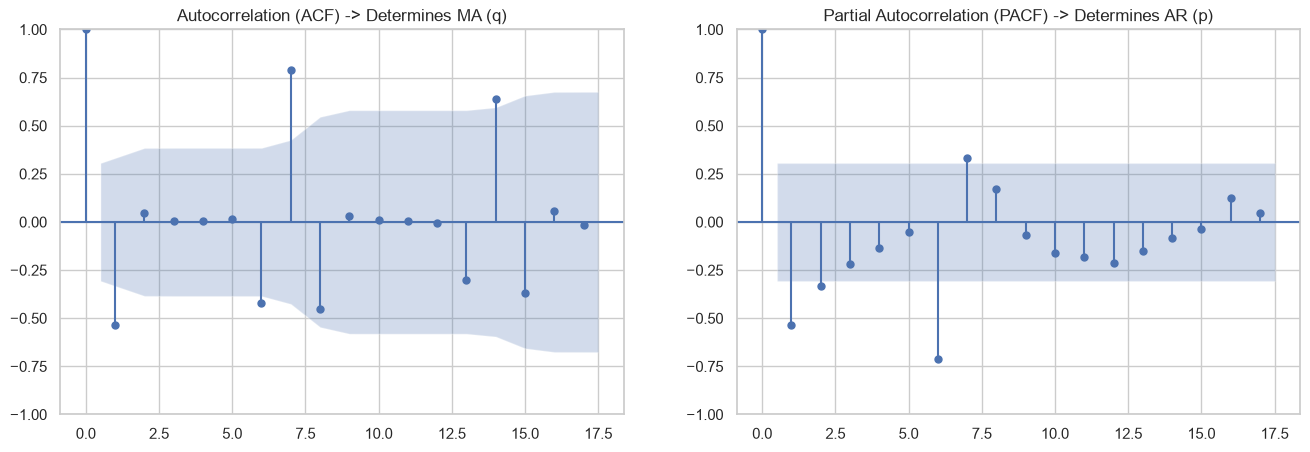

In [39]:
# Step4: Make it stationary and identify. Run ADF, difference as needed, re-test, then read ACF
#and PACF to propose an order before fitting anything.
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Initial ADF Test
result = adfuller(forecasts['Actual'])
print(f"Initial ADF p-value: {result[1]:.4f}")

# Differencing (if p-value >= 0.05)
forecasts['Actual_diff'] = forecasts['Actual'].diff().dropna()

# Re-test Stationarity
result_diff = adfuller(forecasts['Actual_diff'].dropna())
print(f"Differenced ADF p-value: {result_diff[1]:.4f}")

# Plot ACF and PACF to identify orders
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
plot_acf(forecasts['Actual_diff'].dropna(), ax=ax[0])
plot_pacf(forecasts['Actual_diff'].dropna(), ax=ax[1])

ax[0].set_title('Autocorrelation (ACF) -> Determines MA (q)')
ax[1].set_title('Partial Autocorrelation (PACF) -> Determines AR (p)')
plt.show()

In [58]:
# Step5:  Fit, evaluate, recommend. Fit your model, score it on the same holdout, inspect
# residuals, backtest on rolling origins, and write the recommendation.
final_model = SARIMAX(
    train['Sales'],
    order=(1,1,1),
    seasonal_order=(1,1,1,7),
    enforce_stationarity= False,
    enforce_invertibility= False
)
final_fit = final_model.fit()
print (final_fit.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             Sales   No. Observations:                  900
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -7501.949
Date:                           Tue, 20 Oct 2026   AIC                          15013.897
Time:                                   20:57:35   BIC                          15037.814
Sample:                               01-01-2013   HQIC                         15023.042
                                    - 06-19-2015                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1814      0.018      9.904      0.000       0.146       0.217
ma.L1         -0.9520      0.008   -116.935

In [59]:
# forecast over the test set - SCORE ON HOLDOUT
forecast_res = final_fit.get_forecast(steps=len(test))
forecast_df = forecast_res.summary_frame()

#compute the accuracy metrics
y_true = test ['Sales']
y_pred = forecast_df ['mean']

mae = mean_absolute_error ( y_true, y_pred)
rmse = (root_mean_squared_error (y_true, y_pred))
mape = mean_absolute_percentage_error (y_true, y_pred) 

print("-----Model Evaluation Metrics-----")
print(f"MAE : {mae:.2F}")
print(f"RMSE : {rmse:.2F}")
print(f"MAPE : {mape *100:.2F}%")

-----Model Evaluation Metrics-----
MAE : 605.87
RMSE : 723.69
MAPE : 17819347566762393600.00%


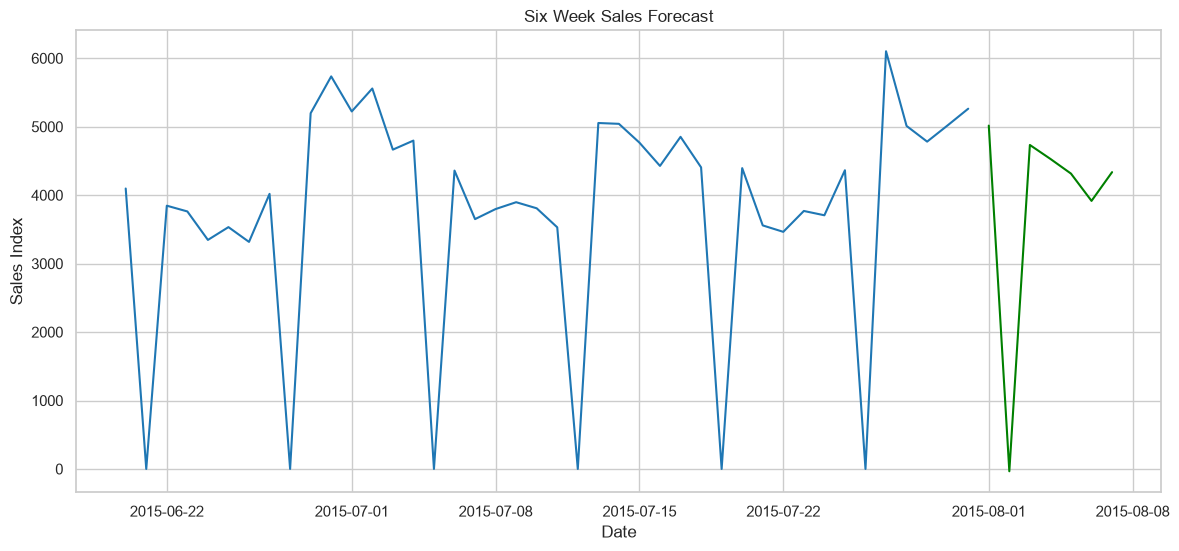

In [46]:
# 42 days for a 6-week holdout
plt.figure(figsize= (14,6))
plt.plot(df_store.index[-42:], df_store['Sales'][-42:], label = "Rossmann Store Observe Data", color = "#1f77b4")
plt.plot(forecast_df.index, forecast_df['mean'], label = "Six Week Ahead", color = "green")

plt.title("Six Week Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales Index")
plt.show()

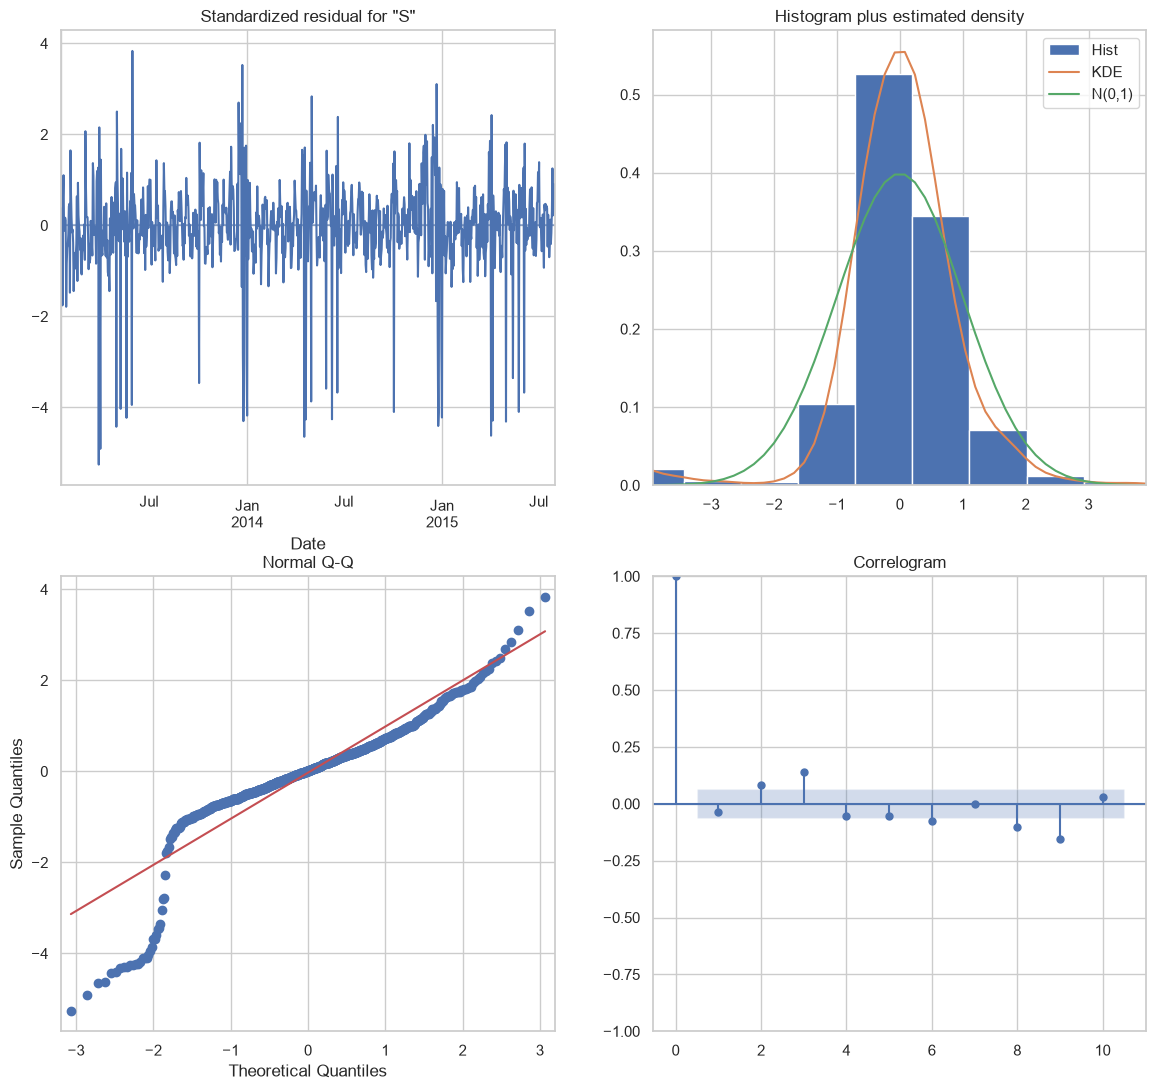

In [57]:
# Visualize Residual Diagnostics
final_fit.plot_diagnostics( figsize=(14, 13))
plt.show()

In [45]:
forecast_holdout = final_fit.get_forecast (steps= 7)
forecast_df = forecast_holdout.summary_frame()

forecast_df

Sales,mean,mean_se,mean_ci_lower,mean_ci_upper
2015-08-01,5016.048507,1134.955315,2791.576965,7240.520049
2015-08-02,-33.822521,1165.879555,-2318.904459,2251.259417
2015-08-03,4733.203333,1170.445357,2439.172587,7027.234078
2015-08-04,4529.259102,1172.693940,2230.821214,6827.696989
2015-08-05,4314.881379,1174.588417,2012.730385,6617.032372
2015-08-06,3916.222641,1176.417295,1610.487112,6221.958170
2015-08-07,4336.214168,1178.234447,2026.917086,6645.511251


In [71]:
# Final Recommedation Summary Table
summary_table = pd.DataFrame({
    "Forecasted Sales": forecast_df['mean'].round(2),
    "Lower CI (95%)" :  forecast_df['mean_ci_lower'].round(2),
    "Upper CI (95%)" :  forecast_df['mean_ci_upper'].round(2)
}, index=test.index)

print("--- Final Recommendation Forecast Matrix ---")
print(summary_table.head(7))

--- Final Recommendation Forecast Matrix ---
            Forecasted Sales  Lower CI (95%)  Upper CI (95%)
Date                                                        
2015-06-20           4696.45         2433.77         6959.14
2015-06-21           -284.77        -2606.27         2036.73
2015-06-22           4538.33         2207.98         6868.67
2015-06-23           4334.14         1999.26         6669.03
2015-06-24           4167.33         1828.54         6506.11
2015-06-25           3683.59         1341.02         6026.15
2015-06-26           4162.75         1816.43         6509.08
